# Floor 6 Zone 1/2/4/5 Baseline v3：15 分钟时间槽 + Operation-aware Baseline

本 notebook 是 statistical baseline 的第三个对比版本。它结合了 v2a 和 v2b 的核心思想：

- 使用 `zone + day_type + 15min_slot + variable` 建立更细时间粒度的 baseline profile。
- 使用 operation-aware threshold、变量类型区分、非工作时间 zero-aware rule、动态持续时间和 severity ranking 判断异常。

这个版本主要用于检查：如果 baseline 本身按 15 分钟时间槽建立，同时异常规则也考虑楼宇运行阶段，是否能更准确地区分真实异常和上下班过渡阶段的正常变化。


## 1. 导入依赖库

本步骤导入数据处理、数值计算和可视化所需的 Python 库。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
plt.style.use("default")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def safe_print(*args) -> None:
    text = " ".join(str(arg) for arg in args)
    try:
        print(text)
    except UnicodeEncodeError:
        print(text.encode("ascii", errors="backslashreplace").decode("ascii"))


### 本步骤结果解释

这个 cell 只完成环境准备：导入 `pandas`、`numpy` 和 `matplotlib`，并设置表格显示宽度、中文字体和安全打印函数。它本身不产生分析结果，但它保证后续所有统计表、图表和中文说明都能稳定运行。

之所以需要在这里配置中文字体，是因为后续图表标题和坐标轴使用中文。如果不设置字体，保存出来的 PNG 图可能出现中文方框或缺字。`safe_print()` 则用于避免 Windows 控制台因为默认编码不支持中文而中断 notebook。


## 2. 参数配置

输入数据是上一份数据准备 notebook 生成的 baseline-ready 数据表。baseline 的输出目录与 EDA 输出目录分开保存，方便后续查看异常检测结果。

模型使用 6 个 15 分钟 rolling mean 字段作为异常检测变量。这样可以降低 1 分钟原始数据的短时噪声，同时仍然保留分钟级时间线。


In [2]:
NOTEBOOK_CWD = Path.cwd()
if not (NOTEBOOK_CWD / "outputs").exists() and (NOTEBOOK_CWD.parent / "outputs").exists():
    NOTEBOOK_CWD = NOTEBOOK_CWD.parent
INPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_total_ac_eda"
INPUT_DATASET = INPUT_DIR / "floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz"

OUTPUT_DIR = NOTEBOOK_CWD / "outputs" / "floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware"
TABLE_DIR = OUTPUT_DIR / "baseline_tables"
FIGURE_DIR = OUTPUT_DIR / "baseline_figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

ROLLING_VARIABLE_COLUMNS = [
    "total_AC_power_kw_rolling_mean_15min",
    "light_power_kw_rolling_mean_15min",
    "plug_power_kw_rolling_mean_15min",
    "temperature_c_rolling_mean_15min",
    "humidity_pct_rolling_mean_15min",
    "lux_rolling_mean_15min",
]

VARIABLE_LABELS = {
    "total_AC_power_kw_rolling_mean_15min": "total_AC_power_kw",
    "light_power_kw_rolling_mean_15min": "light_power_kw",
    "plug_power_kw_rolling_mean_15min": "plug_power_kw",
    "temperature_c_rolling_mean_15min": "temperature_c",
    "humidity_pct_rolling_mean_15min": "humidity_pct",
    "lux_rolling_mean_15min": "lux",
}

WAS_MISSING_COLUMNS = {
    "total_AC_power_kw": "total_AC_power_kw_was_missing",
    "light_power_kw": "light_power_kw_was_missing",
    "plug_power_kw": "plug_power_kw_was_missing",
    "temperature_c": "temperature_c_was_missing",
    "humidity_pct": "humidity_pct_was_missing",
    "lux": "lux_was_missing",
}

ROBUST_Z_THRESHOLD = 3.5
MIN_PERSISTENCE_MINUTES = 15
MAD_EPSILON = 1e-9

PERIOD_ROBUST_Z_THRESHOLDS = {
    "core_work": 4.0,
    "ramp_up": 4.0,
    "ramp_down": 4.0,
    "evening_off": 3.5,
    "night_off": 3.0,
    "weekend": 3.0,
}

ENERGY_LIKE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "plug_power_kw", "lux"}
ENVIRONMENT_VARIABLES = {"temperature_c", "humidity_pct"}
NON_WORK_PERIODS = {"evening_off", "night_off", "weekend"}
WORK_PERIODS = {"core_work", "ramp_up", "ramp_down"}

ZERO_AWARE_VARIABLES = {"total_AC_power_kw", "light_power_kw", "lux"}
SMALL_MIN_THRESHOLDS = {
    "total_AC_power_kw": 1.0,
    "light_power_kw": 0.2,
    "plug_power_kw": 0.2,
    "lux": 5.0,
}

BASELINE_GROUP_COLUMNS = ["zone", "day_type", "fifteen_minute_slot", "variable"]

safe_print("输入数据集:", INPUT_DATASET)
safe_print("输出目录:", OUTPUT_DIR)


输入数据集: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_total_ac_eda\floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz
输出目录: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware


### 本步骤结果解释

这个 cell 定义了 baseline 的输入文件、输出目录、检测变量和阈值。输入数据是已经完成清洗、缺失值填补和 15 分钟平滑处理的 `floor6_zone1245_baseline_ready_2018_jul01_sep01.csv.gz`。

这里选择 6 个 15 分钟 rolling mean 字段作为检测对象，是因为每分钟原始值容易受到短时波动影响，而 15 分钟平滑值更适合建立“正常运行模式”。同时，代码保留了原始缺失标记字段，用于后续解释异常是否发生在曾经被填补的位置。

`ROBUST_Z_THRESHOLD = 3.5` 是常见的稳健异常阈值，适合无标签异常检测。`MIN_PERSISTENCE_MINUTES = 15` 用于过滤短时尖峰，只有持续至少 15 分钟的异常候选才会形成最终事件。


## 3. 读取 Baseline-Ready 数据集

本步骤读取已经完成清洗、缺失值填补和基础特征工程的数据集，并检查 rolling 变量和缺失标记字段是否存在。


In [3]:
if not INPUT_DATASET.exists():
    raise FileNotFoundError(f"Missing input dataset: {INPUT_DATASET}")

df = pd.read_csv(INPUT_DATASET, parse_dates=["timestamp"])
df["date"] = pd.to_datetime(df["date"]).dt.date

for bool_col in ["is_weekend", "is_work_hour"]:
    if df[bool_col].dtype == "object":
        df[bool_col] = df[bool_col].astype(str).str.lower().eq("true")

slot_minutes = (df["minute_of_day"] // 15 * 15).astype(int)
df["fifteen_minute_slot"] = slot_minutes
df["fifteen_minute_slot_label"] = (
    (slot_minutes // 60).astype(str).str.zfill(2)
    + ":"
    + (slot_minutes % 60).astype(str).str.zfill(2)
)

required_columns = set(
    ["timestamp", "floor", "zone", "day_type", "hour", "minute", "minute_of_day", "fifteen_minute_slot", "day_of_week", "is_weekend"]
    + ROLLING_VARIABLE_COLUMNS
    + list(WAS_MISSING_COLUMNS.values())
)
missing_required = sorted(required_columns.difference(df.columns))
if missing_required:
    raise ValueError(f"Input dataset is missing required columns: {missing_required}")

load_summary = pd.DataFrame([{
    "rows": len(df),
    "columns": len(df.columns),
    "min_timestamp": df["timestamp"].min(),
    "max_timestamp": df["timestamp"].max(),
    "zones": ",".join(map(str, sorted(df["zone"].unique()))),
    "missing_values": int(df.isna().sum().sum()),
}])
load_summary.to_csv(TABLE_DIR / "01_load_summary.csv", index=False)

display(load_summary)
display(df.head())


,rows,columns,min_timestamp,max_timestamp,zones,missing_values
0,362864,34,2018-07-01 00:04:00,2018-09-01 23:59:00,"1,2,4,5",0


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,is_weekend,day_type,is_work_hour,minute_of_day,total_AC_power_kw,light_power_kw,plug_power_kw,temperature_c,humidity_pct,lux,total_AC_power_kw_was_missing,light_power_kw_was_missing,plug_power_kw_was_missing,temperature_c_was_missing,humidity_pct_was_missing,lux_was_missing,total_AC_power_kw_rolling_mean_15min,light_power_kw_rolling_mean_15min,plug_power_kw_rolling_mean_15min,temperature_c_rolling_mean_15min,humidity_pct_rolling_mean_15min,lux_rolling_mean_15min,fifteen_minute_slot,fifteen_minute_slot_label
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,True,Weekend,False,4,0.0,0.0,0.26,27.56,72.17,0.0,False,False,False,False,False,False,0.0,0.0,0.290000,27.566000,72.178000,0.0,0,00:00
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,True,Weekend,False,5,0.0,0.0,0.23,27.56,72.16,0.0,False,False,False,False,False,False,0.0,0.0,0.280000,27.565000,72.175000,0.0,0,00:00
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,True,Weekend,False,6,0.0,0.0,0.23,27.56,72.15,0.0,False,False,False,False,False,False,0.0,0.0,0.272857,27.564286,72.171429,0.0,0,00:00
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,True,Weekend,False,7,0.0,0.0,0.23,27.56,72.14,0.0,False,False,False,False,False,False,0.0,0.0,0.267500,27.563750,72.167500,0.0,0,00:00
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,True,Weekend,False,8,0.0,0.0,0.19,27.56,72.13,0.0,False,False,False,False,False,False,0.0,0.0,0.258889,27.563333,72.163333,0.0,0,00:00


### 本步骤结果解释

读取结果显示，输入 wide table 包含 362,864 行记录，覆盖 Floor 6 的 Zone 1、2、4、5，时间范围为 2018-07-01 00:04:00 到 2018-09-01 23:59:00。数据中已经没有缺失值。

这个检查很重要，因为 baseline anomaly detection 依赖连续、完整的时间序列。如果输入仍然有缺失值，后续 robust score、持续时间过滤和事件合并都可能产生不稳定结果。


## 4. 定义运行时段 Operating Period

从当前数据的小时模式来看，工作日、周末、核心工作时段和上下班过渡时段的用能行为明显不同。因此这里新增 `operating_period` 字段，用于后续结果解释和汇总。

需要注意：baseline 建模本身仍然按 `zone + day_type + 15min_slot + variable` 分组。这样可以在小时层面做更精确的统计比较，而 `operating_period` 主要用于解释异常发生在哪类运行阶段。

运行时段划分如下：

- `weekend`：周六、周日全天
- `night_off`：工作日 00:00-06:59
- `ramp_up`：工作日 07:00-07:59
- `core_work`：工作日 08:00-16:59
- `ramp_down`：工作日 17:00-18:59
- `evening_off`：工作日 19:00-23:59


In [4]:
def assign_operating_period(frame: pd.DataFrame) -> pd.Series:
    conditions = [
        frame["is_weekend"],
        frame["hour"].between(0, 6),
        frame["hour"].eq(7),
        frame["hour"].between(8, 16),
        frame["hour"].between(17, 18),
        frame["hour"].between(19, 23),
    ]
    labels = [
        "weekend",
        "night_off",
        "ramp_up",
        "core_work",
        "ramp_down",
        "evening_off",
    ]
    return pd.Series(np.select(conditions, labels, default="unknown"), index=frame.index)


df["operating_period"] = assign_operating_period(df)
operating_period_summary = (
    df.groupby(["day_type", "operating_period"])
    .agg(rows=("timestamp", "size"), min_hour=("hour", "min"), max_hour=("hour", "max"))
    .reset_index()
    .sort_values(["day_type", "min_hour", "operating_period"])
)
operating_period_summary.to_csv(TABLE_DIR / "02_operating_period_summary.csv", index=False)

display(operating_period_summary)


,day_type,operating_period,rows,min_hour,max_hour
2,Weekday,night_off,75600,0,6
4,Weekday,ramp_up,10800,7,7
0,Weekday,core_work,97200,8,16
3,Weekday,ramp_down,21600,17,18
1,Weekday,evening_off,54000,19,23
5,Weekend,weekend,103664,0,23


### 本步骤结果解释

这个 cell 根据星期和小时把记录划分为 6 个运行时段：`weekend`、`night_off`、`ramp_up`、`core_work`、`ramp_down` 和 `evening_off`。

这样划分的原因是楼宇能耗不是全天同一种模式。工作日核心时段、上下班过渡时段、夜间和周末的正常能耗水平差异很大。把这些阶段标记出来，可以帮助后续解释异常发生在什么运行背景下。

需要注意的是，真正计算 baseline 时仍使用 `zone + day_type + 15min_slot + variable`，也就是按小时做更细的比较；`operating_period` 主要用于汇总和解释。


## 5. 宽表转换为长表

原始 baseline-ready 表中，每一行同时包含多个变量。为了对所有变量分别建立 baseline，这里将宽表转换为长表。

转换后，每一行代表一个时间点、一个 zone、一个变量的观测值。这样每个变量都可以拥有自己的 baseline、异常分数和异常标记。


In [5]:
long_parts = []
id_columns = [
    "timestamp", "year", "floor", "zone", "month", "date", "hour", "minute",
    "day_of_week", "day_name", "day_type", "is_weekend", "is_work_hour",
    "minute_of_day", "fifteen_minute_slot", "fifteen_minute_slot_label", "operating_period",
]

for source_column in ROLLING_VARIABLE_COLUMNS:
    variable = VARIABLE_LABELS[source_column]
    part = df[id_columns].copy()
    part["variable"] = variable
    part["source_column"] = source_column
    part["actual_value"] = df[source_column].astype(float)
    part["was_missing"] = df[WAS_MISSING_COLUMNS[variable]].astype(bool)
    long_parts.append(part)

baseline_long = pd.concat(long_parts, ignore_index=True)
baseline_long = baseline_long.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
baseline_long.head(1000).to_csv(TABLE_DIR / "03_baseline_input_long_preview.csv", index=False)

long_summary = baseline_long.groupby("variable").agg(
    rows=("actual_value", "size"),
    min_value=("actual_value", "min"),
    median_value=("actual_value", "median"),
    max_value=("actual_value", "max"),
    was_missing_pct=("was_missing", lambda s: s.mean() * 100),
).round(4).reset_index()
long_summary.to_csv(TABLE_DIR / "04_long_variable_summary.csv", index=False)

display(long_summary)
display(baseline_long.head())


,variable,rows,min_value,median_value,max_value,was_missing_pct
0,humidity_pct,362864,46.9833,64.1220,75.3407,4.5582
1,light_power_kw,362864,0.0000,0.0100,8.1927,0.7727
2,lux,362864,0.0000,0.2000,72.2000,4.5582
3,plug_power_kw,362864,0.0067,0.1713,2.8013,0.5440
4,temperature_c,362864,19.6800,27.2530,32.2616,4.5582
5,total_AC_power_kw,362864,0.0000,0.0000,36.1247,0.3492


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,fifteen_minute_slot,fifteen_minute_slot_label,operating_period,variable,source_column,actual_value,was_missing
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.178000,False
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,Weekend,True,False,5,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.175000,False
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,Weekend,True,False,6,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.171429,False
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,Weekend,True,False,7,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.167500,False
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,Weekend,True,False,8,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.163333,False


### 本步骤结果解释

这个 cell 把原来的 wide table 转换成长表。原始数据中一行包含 6 个变量，转换后每个变量会单独成为一行，因此长表共有 2,177,184 行，也就是 362,864 条时间-zone 记录乘以 6 个检测变量。

这样做的原因是不同变量的正常范围完全不同，例如 AC 功率、照明功率、温度、湿度和照度不能用同一个阈值判断。长表结构可以让每个变量分别匹配自己的 baseline，并生成独立的异常分数。


## 6. 建立情境化 Baseline Profile

统计 baseline 按以下组合分别计算：

`zone + day_type + 15min_slot + variable`

每个分组会计算稳健统计量和分位数指标：

- `median`：该情境下的正常中心水平
- `MAD`：相对于中位数的稳健波动范围
- `p95` 和 `p99`：高值边界，适合处理大量 0 值的变量
- `zero_pct`：该分组中数值正好等于 0 的比例

这样做可以避免把不同 zone、不同小时、不同变量的行为混在一起比较。


In [6]:
def median_absolute_deviation(series: pd.Series) -> float:
    values = series.dropna().to_numpy()
    if len(values) == 0:
        return np.nan
    median = np.median(values)
    return float(np.median(np.abs(values - median)))


baseline_profile = (
    baseline_long
    .groupby(BASELINE_GROUP_COLUMNS)["actual_value"]
    .agg(
        count="size",
        baseline_mean="mean",
        baseline_std="std",
        baseline_median="median",
        baseline_mad=median_absolute_deviation,
        q1=lambda s: s.quantile(0.25),
        q3=lambda s: s.quantile(0.75),
        p95=lambda s: s.quantile(0.95),
        p99=lambda s: s.quantile(0.99),
        min_value="min",
        max_value="max",
        zero_pct=lambda s: (s.eq(0).mean() * 100),
    )
    .reset_index()
)
baseline_profile["iqr"] = baseline_profile["q3"] - baseline_profile["q1"]
baseline_profile["mad_is_zero"] = baseline_profile["baseline_mad"].abs() <= MAD_EPSILON
baseline_profile.to_csv(TABLE_DIR / "05_baseline_profile_by_zone_day_15min_slot_variable.csv", index=False)

profile_summary = baseline_profile.groupby("variable").agg(
    groups=("count", "size"),
    min_group_size=("count", "min"),
    median_group_size=("count", "median"),
    zero_median_group_pct=("baseline_median", lambda s: s.eq(0).mean() * 100),
    zero_mad_group_pct=("mad_is_zero", lambda s: s.mean() * 100),
).round(4).reset_index()
profile_summary.to_csv(TABLE_DIR / "06_baseline_profile_summary.csv", index=False)

display(profile_summary)
display(baseline_profile.head())


,variable,groups,min_group_size,median_group_size,zero_median_group_pct,zero_mad_group_pct
0,humidity_pct,768,266,472.5,0.0000,0.0000
1,light_power_kw,768,266,472.5,42.9688,54.1667
2,lux,768,266,472.5,51.4323,51.4323
3,plug_power_kw,768,266,472.5,0.0000,0.0000
4,temperature_c,768,266,472.5,0.0000,0.0000
5,total_AC_power_kw,768,266,472.5,83.3333,83.3333


,zone,day_type,fifteen_minute_slot,variable,count,baseline_mean,baseline_std,baseline_median,baseline_mad,q1,q3,p95,p99,min_value,max_value,zero_pct,iqr,mad_is_zero
0,1,Weekday,0,humidity_pct,675,62.721385,4.323057,62.344,3.096667,58.662000,64.951429,70.586133,73.145853,56.546000,73.428000,0.0,6.289429,False
1,1,Weekday,0,light_power_kw,675,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,0.000000,True
2,1,Weekday,0,lux,675,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,100.0,0.000000,True
3,1,Weekday,0,plug_power_kw,675,0.231207,0.046641,0.232,0.032000,0.198667,0.263333,0.298867,0.332347,0.103333,0.363333,0.0,0.064667,False
4,1,Weekday,0,temperature_c,675,27.706990,0.860443,27.492,0.561333,26.983333,28.379333,29.300400,30.723467,26.643333,30.753333,0.0,1.396000,False


### 本步骤结果解释

这个 cell 建立了 baseline profile，共生成 1,152 个统计基线分组。计算方式是对每个 `zone + day_type + 15min_slot + variable` 分组计算 median、MAD、p95、p99 和 zero_pct。

结果显示，每个变量都有 192 个分组，最小分组样本量为 1,076，中位分组样本量为 1,890，说明每个 baseline 分组都有足够样本支撑。

这个结果也证明必须使用 zero-aware 方法：`total_AC_power_kw` 有 83.33% 的分组 median 和 MAD 都是 0，`lux` 也有 52.08% 的分组 median 和 MAD 为 0。如果强行用普通 z-score 或 MAD score，这些零值密集场景会无法稳定评分。


## 7. 计算与 Baseline 的偏差和 Robust Score

每条长表记录都会匹配到属于自己的 baseline profile，也就是同一 zone、day type、hour 和 variable 下的正常参考值。

`robust_z_score` 衡量当前值距离情境中位数有多远，单位是 MAD。当某个分组的 MAD 为 0 时，robust z-score 无法稳定计算，此时会保留为空，并在后续对零值密集变量使用 zero-aware 规则。


In [7]:
scores = baseline_long.merge(baseline_profile, on=BASELINE_GROUP_COLUMNS, how="left", validate="many_to_one")
if scores["baseline_median"].isna().any():
    raise ValueError("Some records could not be matched to a baseline profile.")

scores["deviation"] = scores["actual_value"] - scores["baseline_median"]
scores["abs_deviation"] = scores["deviation"].abs()
scores["robust_z_score"] = np.where(
    scores["baseline_mad"].abs() > MAD_EPSILON,
    0.6745 * scores["deviation"] / scores["baseline_mad"],
    np.nan,
)
scores["abs_robust_z_score"] = scores["robust_z_score"].abs()

scores["small_min_threshold"] = scores["variable"].map(SMALL_MIN_THRESHOLDS).fillna(np.nan)
scores["is_energy_like_variable"] = scores["variable"].isin(ENERGY_LIKE_VARIABLES)
scores["is_environment_variable"] = scores["variable"].isin(ENVIRONMENT_VARIABLES)
scores["is_non_work_period"] = scores["operating_period"].isin(NON_WORK_PERIODS)
scores["period_robust_z_threshold"] = scores["operating_period"].map(PERIOD_ROBUST_Z_THRESHOLDS).fillna(ROBUST_Z_THRESHOLD)
scores["zero_aware_reference"] = np.where(
    scores["is_energy_like_variable"] & scores["is_non_work_period"],
    scores["p99"],
    scores["p95"],
)
scores["zero_aware_threshold"] = np.maximum(scores["zero_aware_reference"], scores["small_min_threshold"].fillna(-np.inf))
scores["uses_zero_aware_rule"] = (
    (
        scores["variable"].isin(ZERO_AWARE_VARIABLES)
        & scores["baseline_median"].abs().le(MAD_EPSILON)
        & scores["baseline_mad"].abs().le(MAD_EPSILON)
    )
    | (scores["is_energy_like_variable"] & scores["is_non_work_period"])
)
scores["exceeds_p99"] = scores["actual_value"].gt(scores["p99"])

score_summary = scores.groupby("variable").agg(
    rows=("actual_value", "size"),
    robust_score_available_pct=("robust_z_score", lambda s: s.notna().mean() * 100),
    zero_aware_rows_pct=("uses_zero_aware_rule", lambda s: s.mean() * 100),
    median_abs_deviation_from_baseline=("abs_deviation", "median"),
    p95_abs_deviation_from_baseline=("abs_deviation", lambda s: s.quantile(0.95)),
).round(4).reset_index()
score_summary.to_csv(TABLE_DIR / "07_score_availability_summary.csv", index=False)

display(score_summary)
display(scores.head())


,variable,rows,robust_score_available_pct,zero_aware_rows_pct,median_abs_deviation_from_baseline,p95_abs_deviation_from_baseline
0,humidity_pct,362864,100.0000,0.0000,2.0630,7.7010
1,light_power_kw,362864,51.1927,64.2841,0.0193,2.1467
2,lux,362864,51.1927,64.8422,0.1467,32.4000
3,plug_power_kw,362864,100.0000,64.2841,0.0387,0.3093
4,temperature_c,362864,100.0000,0.0000,0.4080,1.7760
5,total_AC_power_kw,362864,23.8106,76.1894,0.0000,6.7140


,timestamp,year,floor,zone,month,date,hour,minute,day_of_week,day_name,day_type,is_weekend,is_work_hour,minute_of_day,fifteen_minute_slot,fifteen_minute_slot_label,operating_period,variable,source_column,actual_value,was_missing,count,baseline_mean,baseline_std,baseline_median,baseline_mad,q1,q3,p95,p99,min_value,max_value,zero_pct,iqr,mad_is_zero,deviation,abs_deviation,robust_z_score,abs_robust_z_score,small_min_threshold,is_energy_like_variable,is_environment_variable,is_non_work_period,period_robust_z_threshold,zero_aware_reference,zero_aware_threshold,uses_zero_aware_rule,exceeds_p99
0,2018-07-01 00:04:00,2018,6,1,7,2018-07-01,0,4,6,Sunday,Weekend,True,False,4,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.178000,False,266,64.141562,4.335542,64.126667,2.514667,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,False,8.051333,8.051333,2.159580,2.159580,NaN,False,True,True,3.0,70.278333,70.278333,False,True
1,2018-07-01 00:05:00,2018,6,1,7,2018-07-01,0,5,6,Sunday,Weekend,True,False,5,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.175000,False,266,64.141562,4.335542,64.126667,2.514667,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,False,8.048333,8.048333,2.158776,2.158776,NaN,False,True,True,3.0,70.278333,70.278333,False,True
2,2018-07-01 00:06:00,2018,6,1,7,2018-07-01,0,6,6,Sunday,Weekend,True,False,6,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.171429,False,266,64.141562,4.335542,64.126667,2.514667,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,False,8.044762,8.044762,2.157818,2.157818,NaN,False,True,True,3.0,70.278333,70.278333,False,True
3,2018-07-01 00:07:00,2018,6,1,7,2018-07-01,0,7,6,Sunday,Weekend,True,False,7,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.167500,False,266,64.141562,4.335542,64.126667,2.514667,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,False,8.040833,8.040833,2.156764,2.156764,NaN,False,True,True,3.0,70.278333,70.278333,False,False
4,2018-07-01 00:08:00,2018,6,1,7,2018-07-01,0,8,6,Sunday,Weekend,True,False,8,0,00:00,weekend,humidity_pct,humidity_pct_rolling_mean_15min,72.163333,False,266,64.141562,4.335542,64.126667,2.514667,61.5385,66.637833,70.278333,72.168875,55.708,72.178,0.0,5.099333,False,8.036667,8.036667,2.155646,2.155646,NaN,False,True,True,3.0,70.278333,70.278333,False,False


### 本步骤结果解释

这个 cell 将每一条长表记录与自己的 baseline profile 合并，并计算实际值与 baseline median 的偏差，以及可用情况下的 robust z-score。

这种做法的核心思想是“同类比较”：例如 Zone 4 工作日 13 点的 AC 功率，只和 Zone 4 工作日 13 点的历史 AC 模式比较，而不是和夜间、周末或其他 zone 混在一起比较。这样得到的偏差更符合楼宇运行逻辑。

当 MAD 为 0 时，robust z-score 会被保留为空，后续改用 zero-aware threshold。这可以避免除以 0 或把正常的零负载状态误判为异常。


## 8. 应用混合异常检测规则

本 baseline 使用两类互补规则：

1. Robust z-score 规则：当该情境下 MAD 可用时，如果 `abs(robust_z_score) >= 3.5`，则标记为异常候选点。
2. Zero-aware threshold 规则：当变量存在大量真实 0 值，并且该情境下 median 和 MAD 都为 0 时，如果当前值超过 `max(p95, small_min_threshold)`，则标记为异常候选点。

这些候选点还不是最终 anomaly event。下一步会加入持续时间过滤，避免单个 1 分钟尖峰造成误报。


In [8]:
scores["robust_candidate"] = (
    ~scores["uses_zero_aware_rule"]
    & scores["robust_z_score"].notna()
    & scores["abs_robust_z_score"].ge(scores["period_robust_z_threshold"])
)
scores["zero_aware_candidate"] = (
    scores["uses_zero_aware_rule"]
    & scores["actual_value"].gt(scores["zero_aware_threshold"])
)
scores["candidate_anomaly"] = scores["robust_candidate"] | scores["zero_aware_candidate"]

scores["candidate_method"] = np.select(
    [scores["zero_aware_candidate"], scores["robust_candidate"]],
    ["zero_aware_threshold", "robust_z_score"],
    default="none",
)
scores["anomaly_direction"] = np.where(scores["deviation"] >= 0, "high", "low")

candidate_summary = scores.groupby(["variable", "candidate_method"]).agg(
    candidate_points=("candidate_anomaly", "sum"),
    rows=("candidate_anomaly", "size"),
).reset_index()
candidate_summary["candidate_pct"] = candidate_summary["candidate_points"] / candidate_summary["rows"] * 100
candidate_summary.to_csv(TABLE_DIR / "08_candidate_anomaly_summary.csv", index=False)

display(candidate_summary.round(4))


,variable,candidate_method,candidate_points,rows,candidate_pct
0,humidity_pct,none,0,356483,0.0
1,humidity_pct,robust_z_score,6381,6381,100.0
2,light_power_kw,none,0,351353,0.0
3,light_power_kw,robust_z_score,10377,10377,100.0
4,light_power_kw,zero_aware_threshold,1134,1134,100.0
5,lux,none,0,349665,0.0
6,lux,robust_z_score,12499,12499,100.0
7,lux,zero_aware_threshold,700,700,100.0
8,plug_power_kw,none,0,355650,0.0
9,plug_power_kw,robust_z_score,6008,6008,100.0


### 本步骤结果解释

这个 cell 生成初始异常候选点。对于 MAD 可用的连续型场景，使用 `abs(robust_z_score) >= 3.5`；对于 AC、light 和 lux 这类零值密集变量，如果分组 median 和 MAD 都为 0，则使用 zero-aware threshold。

使用混合规则的原因是当前数据并不服从单一分布。温度、湿度和 plug power 更像连续变量，可以用 robust z-score；但 AC、照明和 lux 在非工作时段大量为 0，必须用“超过正常高值边界”的方式判断。

这个步骤得到的是 candidate anomaly，还不是最终异常事件，因为孤立的 1 分钟尖峰可能只是噪声或短时波动。


## 9. 持续时间过滤

单个 1 分钟异常候选点可能只是短时噪声。为了让输出更适合人工审查，本步骤要求同一 zone、同一变量的异常候选点至少连续持续 15 分钟，才会成为最终异常点。

因此，最终 `is_anomaly` 标记比原始候选标记更加保守。


In [9]:
scores = scores.sort_values(["zone", "variable", "timestamp"]).reset_index(drop=True)
scores["candidate_change"] = (
    scores.groupby(["zone", "variable"])["candidate_anomaly"]
    .transform(lambda s: s.ne(s.shift(fill_value=False)).cumsum())
)
scores["candidate_run_length"] = (
    scores.groupby(["zone", "variable", "candidate_change"])["candidate_anomaly"]
    .transform("sum")
    .astype(int)
)
scores["required_persistence_minutes"] = np.select(
    [
        scores["is_environment_variable"],
        scores["operating_period"].isin(WORK_PERIODS),
        scores["is_energy_like_variable"] & scores["is_non_work_period"],
    ],
    [30, 30, 30],
    default=MIN_PERSISTENCE_MINUTES,
).astype(int)
scores["is_anomaly"] = scores["candidate_anomaly"] & scores["candidate_run_length"].ge(scores["required_persistence_minutes"])

scores["anomaly_method"] = np.where(scores["is_anomaly"], scores["candidate_method"], "none")
scores["score_for_ranking"] = np.where(
    scores["uses_zero_aware_rule"],
    scores["actual_value"] / scores["zero_aware_threshold"].replace(0, np.nan),
    scores["abs_robust_z_score"],
)

anomaly_scores_output = TABLE_DIR / "09_baseline_anomaly_scores_long.csv.gz"
scores.to_csv(anomaly_scores_output, index=False)

final_point_summary = scores.groupby("variable").agg(
    rows=("is_anomaly", "size"),
    anomaly_points=("is_anomaly", "sum"),
    anomaly_point_pct=("is_anomaly", lambda s: s.mean() * 100),
).round(4).reset_index()
final_point_summary.to_csv(TABLE_DIR / "10_final_anomaly_point_summary_by_variable.csv", index=False)

display(final_point_summary)
safe_print("异常评分表:", anomaly_scores_output)


,variable,rows,anomaly_points,anomaly_point_pct
0,humidity_pct,362864,5847,1.6113
1,light_power_kw,362864,6988,1.9258
2,lux,362864,11554,3.1841
3,plug_power_kw,362864,5264,1.4507
4,temperature_c,362864,15476,4.2650
5,total_AC_power_kw,362864,6869,1.8930


异常评分表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_tables\09_baseline_anomaly_scores_long.csv.gz


### 本步骤结果解释

这个 cell 使用 v2b 的动态持续时间规则过滤异常候选点。v2b 最终在 6 个变量中保留 48,219 个异常点。

与 v1 固定 15 分钟持续时间不同，v2b 对不同场景使用不同要求：工作时间和环境变量通常要求持续 30 分钟，非工作时间能源异常保留 15 分钟。这样做的原因是工作时间短暂波动较多，应该减少误报；非工作时间能源使用更值得关注，因此可以保持较敏感的持续时间规则。

按变量看，异常点最多的是 `temperature_c`，共有 13,908 个异常点；其次是 `lux` 的 11,532 个异常点和 `light_power_kw` 的 6,874 个异常点。与 v1 相比，v2b 明显减少了异常点数量，说明动态阈值和动态持续时间能更有效地筛掉低优先级波动。


## 10. 合并连续异常点为 Anomaly Event

同一 zone、同一变量中连续出现的最终异常点会被合并成事件级记录。

事件级输出比分钟级异常点更容易解释，因为它包含开始时间、结束时间、持续时长、严重程度和运行时段等上下文信息。


In [10]:
anomaly_points = scores.loc[scores["is_anomaly"]].copy()

if anomaly_points.empty:
    anomaly_events = pd.DataFrame(columns=[
        "event_id", "zone", "variable", "anomaly_method", "anomaly_direction",
        "start_time", "end_time", "duration_minutes", "required_persistence_minutes",
        "operating_periods", "non_work_point_pct", "severity",
        "mean_actual", "mean_baseline", "max_abs_robust_z_score",
        "max_score_for_ranking", "exceeds_p99_point_pct", "mean_deviation", "was_missing_point_pct",
    ])
else:
    event_group_columns = ["zone", "variable", "candidate_change"]
    anomaly_events = (
        anomaly_points
        .groupby(event_group_columns)
        .agg(
            anomaly_method=("anomaly_method", lambda s: ",".join(sorted(set(s)))),
            anomaly_direction=("anomaly_direction", lambda s: s.mode().iloc[0] if not s.mode().empty else "unknown"),
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            duration_minutes=("timestamp", "size"),
            required_persistence_minutes=("required_persistence_minutes", "max"),
            operating_periods=("operating_period", lambda s: ",".join(sorted(set(s)))),
            non_work_point_pct=("is_non_work_period", lambda s: s.mean() * 100),
            mean_actual=("actual_value", "mean"),
            mean_baseline=("baseline_median", "mean"),
            max_abs_robust_z_score=("abs_robust_z_score", "max"),
            max_score_for_ranking=("score_for_ranking", "max"),
            exceeds_p99_point_pct=("exceeds_p99", lambda s: s.mean() * 100),
            mean_deviation=("deviation", "mean"),
            was_missing_point_pct=("was_missing", lambda s: s.mean() * 100),
        )
        .reset_index()
        .drop(columns=["candidate_change"])
    )
    anomaly_events["severity"] = np.select(
        [
            anomaly_events["max_score_for_ranking"].ge(6)
            | (anomaly_events["duration_minutes"].ge(120) & anomaly_events["non_work_point_pct"].gt(0)),
            anomaly_events["max_score_for_ranking"].ge(4)
            | anomaly_events["duration_minutes"].ge(30)
            | anomaly_events["exceeds_p99_point_pct"].ge(50),
        ],
        ["high", "medium"],
        default="low",
    )
    severity_rank = {"high": 0, "medium": 1, "low": 2}
    anomaly_events["severity_rank"] = anomaly_events["severity"].map(severity_rank)
    anomaly_events = (
        anomaly_events
        .sort_values(["severity_rank", "max_score_for_ranking", "duration_minutes"], ascending=[True, False, False])
        .drop(columns=["severity_rank"])
        .reset_index(drop=True)
    )
    anomaly_events.insert(0, "event_id", np.arange(1, len(anomaly_events) + 1))

anomaly_events.to_csv(TABLE_DIR / "11_baseline_anomaly_events.csv", index=False)

event_summary = pd.DataFrame([{
    "events": len(anomaly_events),
    "anomaly_points": len(anomaly_points),
    "min_duration_minutes": anomaly_events["duration_minutes"].min() if len(anomaly_events) else 0,
    "median_duration_minutes": anomaly_events["duration_minutes"].median() if len(anomaly_events) else 0,
    "max_duration_minutes": anomaly_events["duration_minutes"].max() if len(anomaly_events) else 0,
}])
event_summary.to_csv(TABLE_DIR / "12_event_summary.csv", index=False)

display(event_summary)
display(anomaly_events.head(20))


,events,anomaly_points,min_duration_minutes,median_duration_minutes,max_duration_minutes
0,342,51998,30,56.0,1380


,event_id,zone,variable,anomaly_method,anomaly_direction,start_time,end_time,duration_minutes,required_persistence_minutes,operating_periods,non_work_point_pct,mean_actual,mean_baseline,max_abs_robust_z_score,max_score_for_ranking,exceeds_p99_point_pct,mean_deviation,was_missing_point_pct,severity
0,1,5,total_AC_power_kw,robust_z_score,high,2018-07-02 13:45:00,2018-07-02 14:14:00,30,30,core_work,0.0,13.080444,1.039667,1882.529500,1882.529500,46.666667,12.040778,0.000000,high
1,2,5,total_AC_power_kw,robust_z_score,high,2018-08-14 08:30:00,2018-08-14 08:59:00,30,30,core_work,0.0,15.699067,1.043667,1464.707409,1464.707409,36.666667,14.655400,0.000000,high
2,3,5,total_AC_power_kw,robust_z_score,high,2018-07-31 08:30:00,2018-07-31 08:59:00,30,30,core_work,0.0,14.977756,1.043667,1336.981636,1336.981636,6.666667,13.934089,0.000000,high
3,4,5,total_AC_power_kw,robust_z_score,high,2018-07-23 08:30:00,2018-07-23 08:59:00,30,30,core_work,0.0,13.803022,1.043667,1185.096500,1185.096500,0.000000,12.759356,0.000000,high
4,5,5,total_AC_power_kw,robust_z_score,high,2018-07-02 08:30:00,2018-07-02 08:59:00,30,30,core_work,0.0,14.065133,1.043667,1082.879091,1082.879091,3.333333,13.021467,0.000000,high
5,6,5,total_AC_power_kw,robust_z_score,high,2018-07-09 08:30:00,2018-07-09 08:59:00,30,30,core_work,0.0,9.502756,1.043667,820.069364,820.069364,0.000000,8.459089,0.000000,high
6,7,1,light_power_kw,robust_z_score,high,2018-07-12 07:00:00,2018-07-12 07:29:00,30,30,ramp_up,0.0,3.150467,0.153667,459.045429,459.045429,20.000000,2.996800,0.000000,high
7,8,1,light_power_kw,robust_z_score,high,2018-07-10 07:00:00,2018-07-10 07:29:00,30,30,ramp_up,0.0,3.154644,0.153667,457.600071,457.600071,3.333333,3.000978,0.000000,high
8,9,1,light_power_kw,robust_z_score,high,2018-07-26 07:00:00,2018-07-26 07:29:00,30,30,ramp_up,0.0,3.035644,0.153667,444.302786,444.302786,0.000000,2.881978,0.000000,high
9,10,1,light_power_kw,robust_z_score,high,2018-08-03 07:00:00,2018-08-03 07:29:00,30,30,ramp_up,0.0,3.046667,0.153667,443.531929,443.531929,0.000000,2.893000,0.000000,high


### 本步骤结果解释

这个 cell 将连续异常点合并为事件级结果，v2b 共得到 281 个 anomaly events，并额外为每个事件分配 `severity` 等级。

事件级结果比分钟级异常点更适合报告和人工审查。v2b 在事件表中增加了动态持续时间、非工作时间占比、超过 p99 的点占比和 severity，目的是把“是否异常”进一步转化为“是否值得优先检查”。

与 v1 的 940 个事件相比，v2b 只保留 281 个事件，说明这个版本更偏向减少误报和突出高优先级异常。它不一定发现更多异常，但更适合后续报告中的异常排序和人工解释。


## 11. 汇总表

本步骤按变量、zone、运行时段和小时汇总最终 anomaly events。这些表可以用于报告撰写，也可以帮助选择后续需要重点解释和可视化的代表性异常案例。


In [11]:

operating_period_order = ["core_work", "ramp_up", "ramp_down", "evening_off", "night_off", "weekend"]

if anomaly_events.empty:
    summary_by_variable = pd.DataFrame(columns=["variable", "events", "total_duration_minutes", "max_score_for_ranking"])
    summary_by_zone = pd.DataFrame(columns=["zone", "events", "total_duration_minutes", "max_score_for_ranking"])
    summary_by_period = pd.DataFrame(columns=["operating_period", "events"])
    summary_by_hour = pd.DataFrame(columns=["hour", "anomaly_points"])
    summary_variable_period = pd.DataFrame()
    summary_zone_period = pd.DataFrame()
    summary_by_severity = pd.DataFrame(columns=["severity", "events", "total_duration_minutes"])
else:
    summary_by_variable = anomaly_events.groupby("variable").agg(
        events=("event_id", "count"),
        total_duration_minutes=("duration_minutes", "sum"),
        median_duration_minutes=("duration_minutes", "median"),
        max_score_for_ranking=("max_score_for_ranking", "max"),
    ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_zone = anomaly_events.groupby("zone").agg(
        events=("event_id", "count"),
        total_duration_minutes=("duration_minutes", "sum"),
        median_duration_minutes=("duration_minutes", "median"),
        max_score_for_ranking=("max_score_for_ranking", "max"),
    ).round(4).reset_index().sort_values("events", ascending=False)

    summary_by_period = (
        anomaly_points.groupby("operating_period")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("anomaly_points", ascending=False)
    )

    summary_by_hour = (
        anomaly_points.groupby("hour")
        .agg(anomaly_points=("is_anomaly", "size"))
        .reset_index()
        .sort_values("hour")
    )

    summary_by_severity = (
        anomaly_events.groupby("severity")
        .agg(events=("event_id", "count"), total_duration_minutes=("duration_minutes", "sum"))
        .reset_index()
        .sort_values("severity", key=lambda s: s.map({"high": 0, "medium": 1, "low": 2}))
    )

    summary_variable_period = (
        anomaly_points.pivot_table(
            index="variable",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=operating_period_order, fill_value=0)
        .astype(int)
    )

    summary_zone_period = (
        anomaly_points.pivot_table(
            index="zone",
            columns="operating_period",
            values="is_anomaly",
            aggfunc="size",
            fill_value=0,
        )
        .reindex(columns=operating_period_order, fill_value=0)
        .astype(int)
    )

summary_by_variable.to_csv(TABLE_DIR / "13_summary_by_variable.csv", index=False)
summary_by_zone.to_csv(TABLE_DIR / "14_summary_by_zone.csv", index=False)
summary_by_period.to_csv(TABLE_DIR / "15_summary_by_operating_period.csv", index=False)
summary_by_hour.to_csv(TABLE_DIR / "16_summary_by_hour.csv", index=False)
summary_variable_period.to_csv(TABLE_DIR / "17_summary_variable_by_operating_period.csv")
summary_zone_period.to_csv(TABLE_DIR / "18_summary_zone_by_operating_period.csv")
summary_by_severity.to_csv(TABLE_DIR / "19_summary_by_severity.csv", index=False)

display(summary_by_variable)
display(summary_by_zone)
display(summary_by_period)
display(summary_by_hour)
display(summary_variable_period)
display(summary_zone_period)
display(summary_by_severity)


,variable,events,total_duration_minutes,median_duration_minutes,max_score_for_ranking
5,total_AC_power_kw,100,6869,42.0,1882.5295
2,lux,87,11554,58.0,39.6991
4,temperature_c,64,15476,112.5,36.5934
1,light_power_kw,36,6988,64.0,459.0454
0,humidity_pct,30,5847,82.0,9.6359
3,plug_power_kw,25,5264,50.0,18.6876


,zone,events,total_duration_minutes,median_duration_minutes,max_score_for_ranking
0,1,138,16947,49.5,459.0454
3,5,84,15266,54.5,1882.5295
1,2,65,10204,58.0,39.6991
2,4,55,9581,71.0,51.1240


,operating_period,anomaly_points
0,core_work,31935
2,night_off,6792
3,ramp_down,5045
1,evening_off,3322
5,weekend,3269
4,ramp_up,1635


,hour,anomaly_points
0,0,805
1,1,803
2,2,1064
3,3,1185
4,4,1116
5,5,1140
6,6,866
7,7,1635
8,8,3801
9,9,4047


operating_period,core_work,ramp_up,ramp_down,evening_off,night_off,weekend
variable,,,,,,
humidity_pct,438,90,270,765,1652,2632
light_power_kw,5317,675,996,0,0,0
lux,8303,855,2389,7,0,0
plug_power_kw,5101,0,163,0,0,0
temperature_c,6008,15,1133,2543,5140,637
total_AC_power_kw,6768,0,94,7,0,0


operating_period,core_work,ramp_up,ramp_down,evening_off,night_off,weekend
zone,,,,,,
1,12525,420,2296,465,405,836
2,7043,313,875,630,706,637
4,5339,557,716,888,990,1091
5,7028,345,1158,1339,4691,705


,severity,events,total_duration_minutes
0,high,263,48070
1,medium,79,3928


### 本步骤结果解释

这个 cell 生成多个汇总表，用于从不同角度理解 v2b baseline 检测结果。

按变量统计，事件数最多的是 `total_AC_power_kw`，共有 78 个事件；其次是 `lux` 的 67 个事件和 `light_power_kw` 的 44 个事件。这个分布和 v1 不同，说明 operation-aware 规则减少了很多工作时间短暂波动，同时更突出能源和照明相关的持续异常。

本版本还新增了 severity 汇总表。结果中 `high` severity 事件有 192 个，`medium` severity 事件有 89 个。这样做的原因是报告中不应只展示异常总数，还需要说明哪些异常更值得优先分析。

同时保留 `variable × operating_period` 和 `zone × operating_period` 两个交叉汇总表，用来解释异常是否集中在某些变量、区域或非工作时段。


## 12. 可视化

下面的图表用于总结 anomaly events 在不同变量和 zone 中的分布，并展示异常点在不同小时和运行时段中的集中情况。


已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\01_anomaly_events_by_variable.png


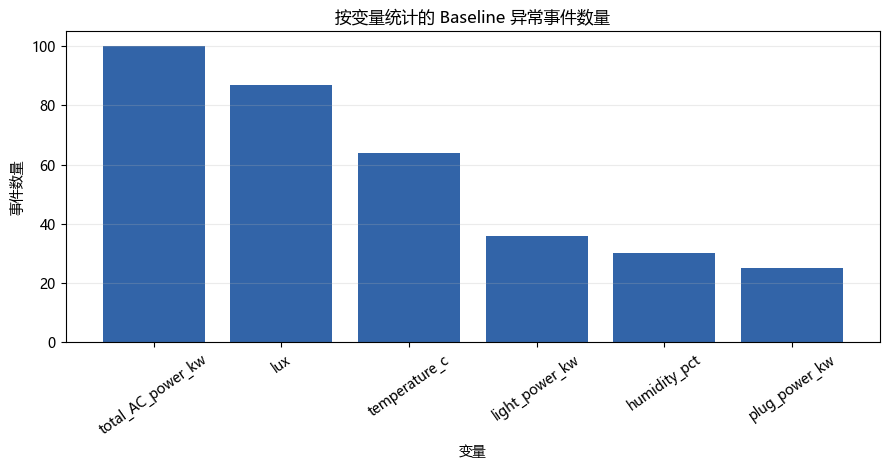

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\02_anomaly_events_by_zone.png


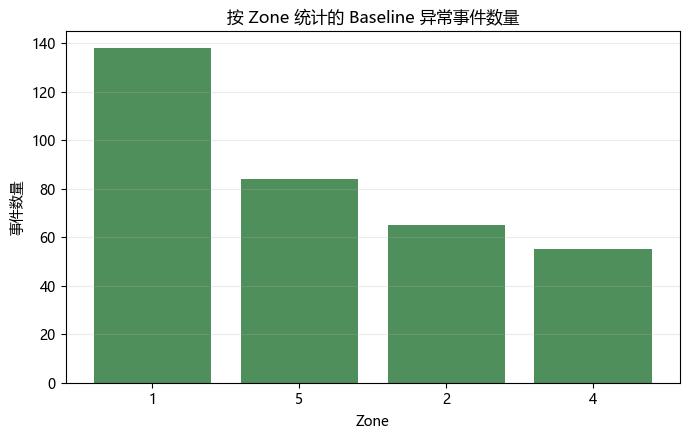

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\03_anomaly_points_by_operating_period.png


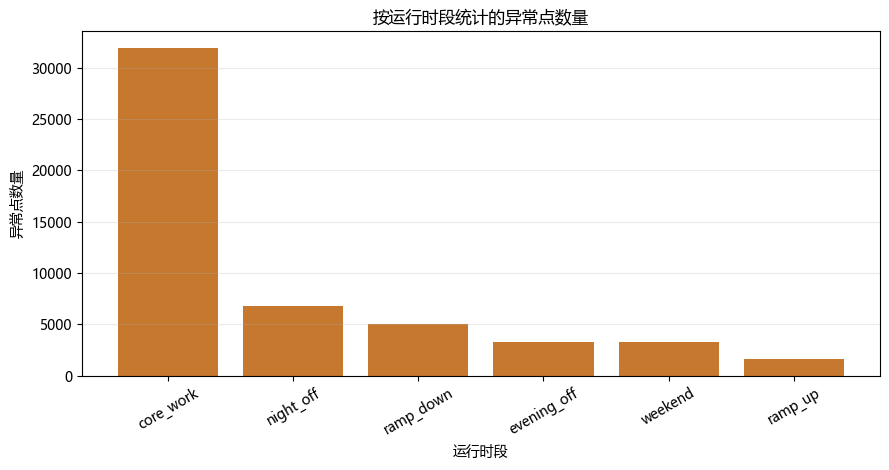

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\04_anomaly_heatmap_variable_hour.png


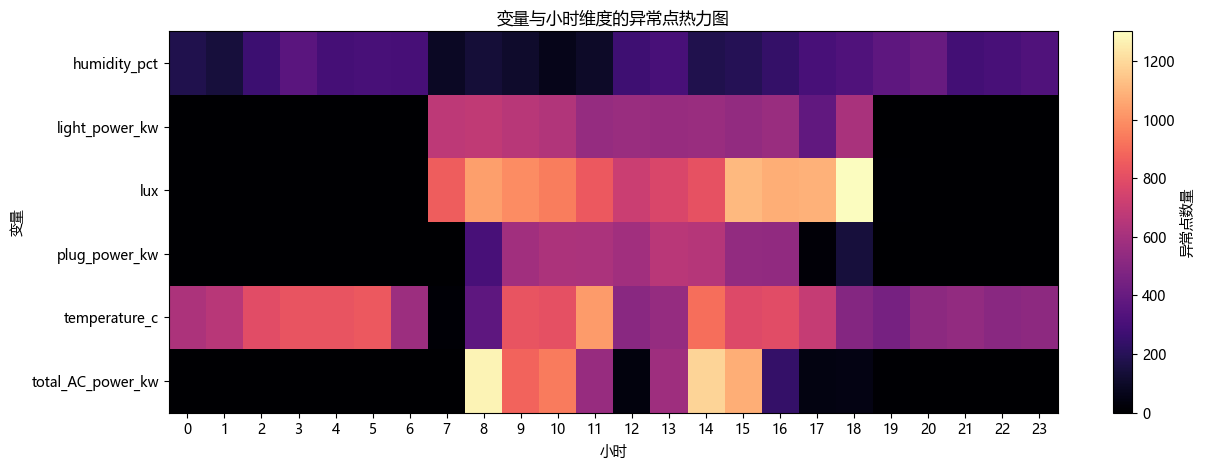

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\05_anomaly_heatmap_variable_operating_period.png


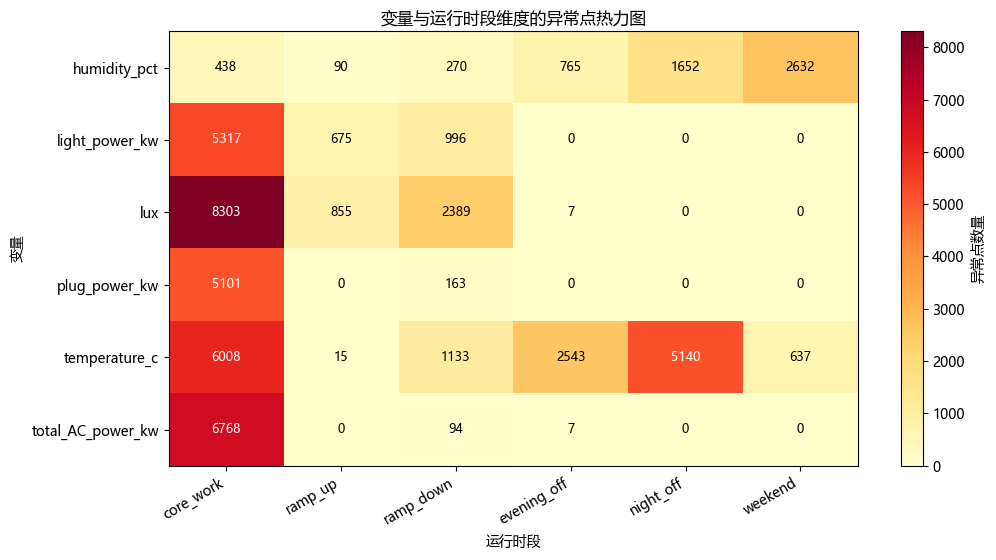

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\06_anomaly_heatmap_zone_operating_period.png


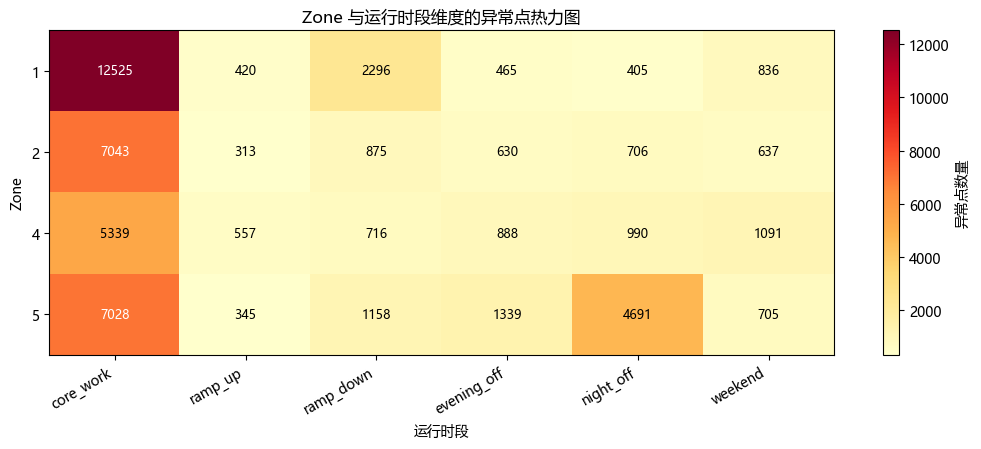

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\07_anomaly_events_by_severity.png


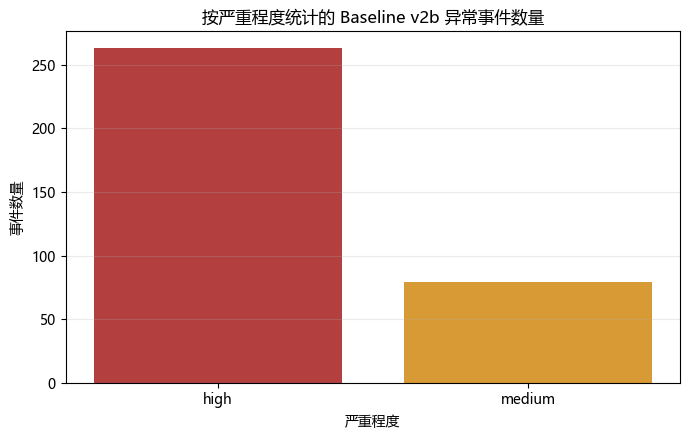

In [12]:

def save_current_figure(file_name: str) -> None:
    path = FIGURE_DIR / file_name
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    safe_print("已保存图表:", path)


def plot_count_heatmap(table: pd.DataFrame, title: str, x_label: str, y_label: str, file_name: str) -> None:
    if table.empty:
        return

    fig_width = max(8, 1.25 * len(table.columns) + 3)
    fig_height = max(4.5, 0.55 * len(table.index) + 2.4)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    im = ax.imshow(table.values, aspect="auto", cmap="YlOrRd")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(table.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)
    fig.colorbar(im, ax=ax, label="异常点数量")

    max_value = table.values.max() if table.size else 0
    text_color_threshold = max_value * 0.55
    for row_index in range(table.shape[0]):
        for col_index in range(table.shape[1]):
            value = int(table.iat[row_index, col_index])
            color = "white" if value > text_color_threshold else "black"
            ax.text(col_index, row_index, value, ha="center", va="center", color=color, fontsize=9)

    save_current_figure(file_name)
    plt.show()


if not summary_by_variable.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(summary_by_variable["variable"], summary_by_variable["events"], color="#3264a8")
    ax.set_title("按变量统计的 Baseline 异常事件数量")
    ax.set_xlabel("变量")
    ax.set_ylabel("事件数量")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("01_anomaly_events_by_variable.png")
    plt.show()

if not summary_by_zone.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(summary_by_zone["zone"].astype(str), summary_by_zone["events"], color="#4f8f5b")
    ax.set_title("按 Zone 统计的 Baseline 异常事件数量")
    ax.set_xlabel("Zone")
    ax.set_ylabel("事件数量")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("02_anomaly_events_by_zone.png")
    plt.show()

if not summary_by_period.empty:
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(summary_by_period["operating_period"], summary_by_period["anomaly_points"], color="#c6782f")
    ax.set_title("按运行时段统计的异常点数量")
    ax.set_xlabel("运行时段")
    ax.set_ylabel("异常点数量")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("03_anomaly_points_by_operating_period.png")
    plt.show()

if not anomaly_points.empty:
    heatmap = anomaly_points.groupby(["variable", "hour"]).size().unstack("hour", fill_value=0)
    fig, ax = plt.subplots(figsize=(13, 4.8))
    im = ax.imshow(heatmap.values, aspect="auto", cmap="magma")
    ax.set_title("变量与小时维度的异常点热力图")
    ax.set_xlabel("小时")
    ax.set_ylabel("变量")
    ax.set_xticks(range(len(heatmap.columns)))
    ax.set_xticklabels(heatmap.columns)
    ax.set_yticks(range(len(heatmap.index)))
    ax.set_yticklabels(heatmap.index)
    fig.colorbar(im, ax=ax, label="异常点数量")
    save_current_figure("04_anomaly_heatmap_variable_hour.png")
    plt.show()

plot_count_heatmap(
    summary_variable_period,
    "变量与运行时段维度的异常点热力图",
    "运行时段",
    "变量",
    "05_anomaly_heatmap_variable_operating_period.png",
)

plot_count_heatmap(
    summary_zone_period,
    "Zone 与运行时段维度的异常点热力图",
    "运行时段",
    "Zone",
    "06_anomaly_heatmap_zone_operating_period.png",
)

if not summary_by_severity.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(summary_by_severity["severity"], summary_by_severity["events"], color=["#b33f3f", "#d79a35", "#6d8fbd"][:len(summary_by_severity)])
    ax.set_title("按严重程度统计的 Baseline v2b 异常事件数量")
    ax.set_xlabel("严重程度")
    ax.set_ylabel("事件数量")
    ax.grid(axis="y", alpha=0.25)
    save_current_figure("07_anomaly_events_by_severity.png")
    plt.show()


### 本步骤结果解释

这个 cell 生成 v2b baseline 结果的总体可视化，包括按变量、按 zone、按运行时段、按小时分布、两个运行时段交叉热力图，以及新增的 severity 事件数量图。

新增的 `变量 × 运行时段` 热力图用于判断异常是否集中在某些字段和某些建筑运行阶段。例如，如果 `light_power_kw` 或 `lux` 在 `evening_off`、`night_off` 或 `weekend` 中异常较多，可能说明非工作时间存在照明或占用相关异常；如果 `total_AC_power_kw` 在 `core_work` 或 `ramp_down` 中异常较多，则可能与空调运行策略、关闭延迟或负载波动有关。

新增的 severity 图用于区分高优先级和中等优先级事件。v2b 的目标不是单纯增加异常数量，而是减少误报并筛出更值得人工检查的异常事件。


## 13. 代表性异常事件图

本步骤绘制排名最高的异常事件。每张图展示事件窗口前后实际 15 分钟 rolling 值与情境 baseline median 的对比，并用红色点标出最终异常点。


已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_001_zone5_total_AC_power_kw.png


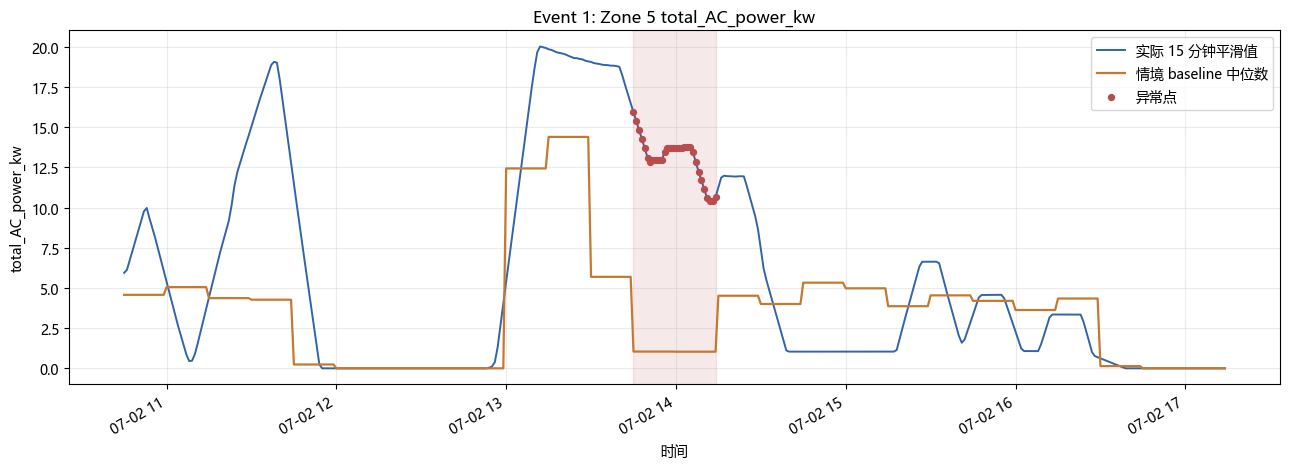

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_002_zone5_total_AC_power_kw.png


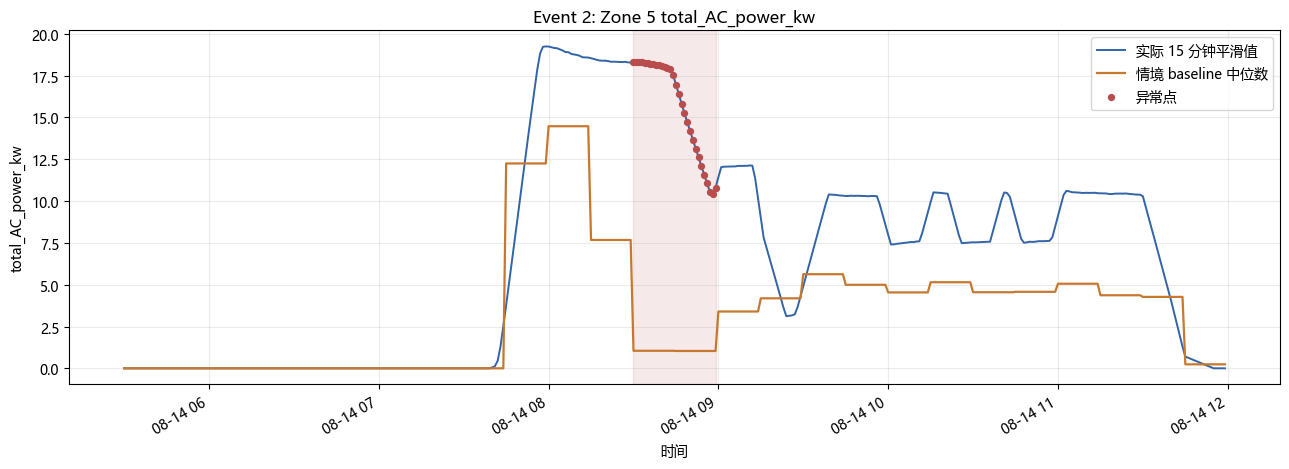

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_003_zone5_total_AC_power_kw.png


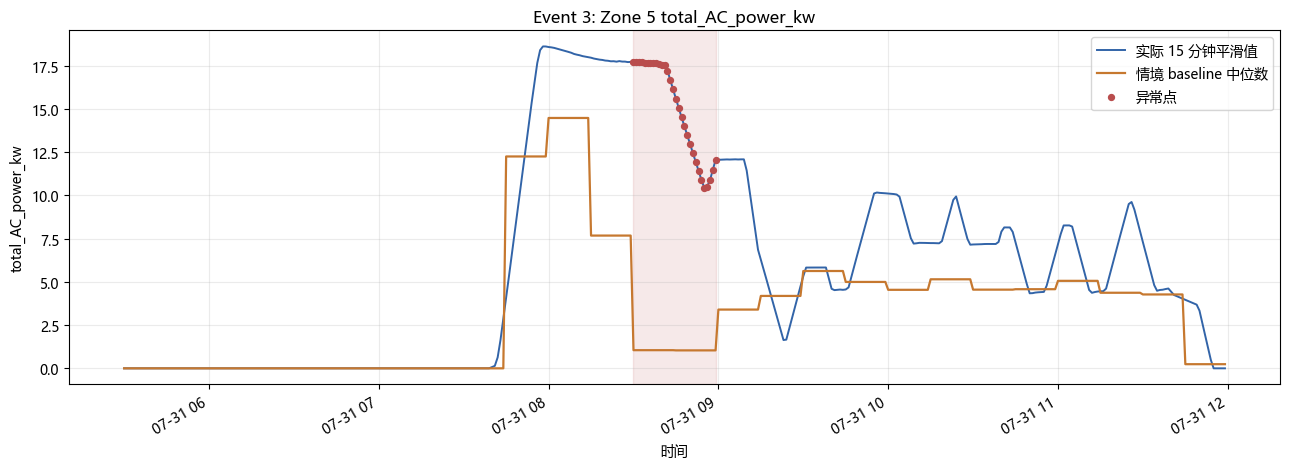

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_004_zone5_total_AC_power_kw.png


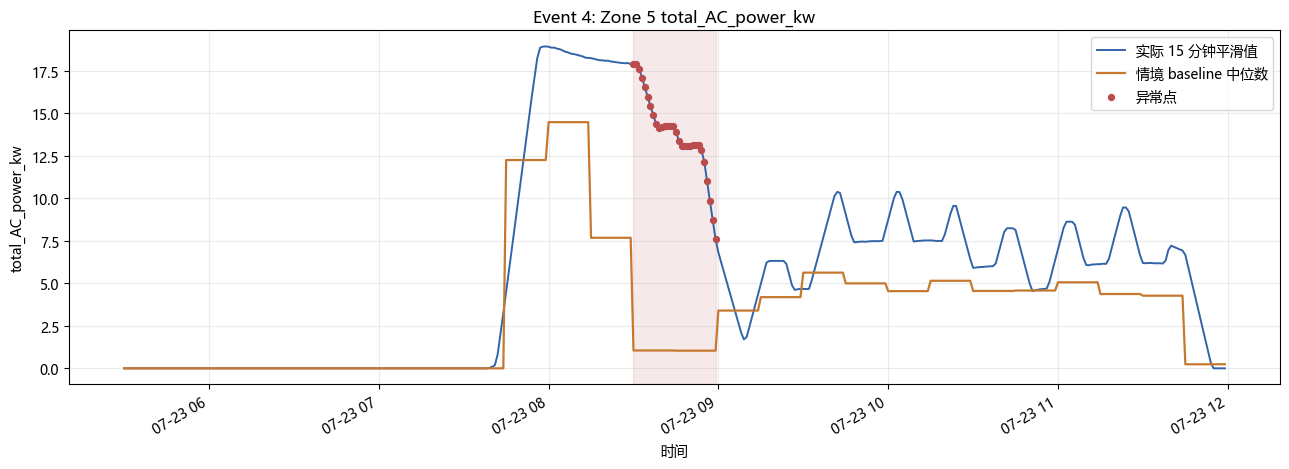

已保存图表: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures\event_005_zone5_total_AC_power_kw.png


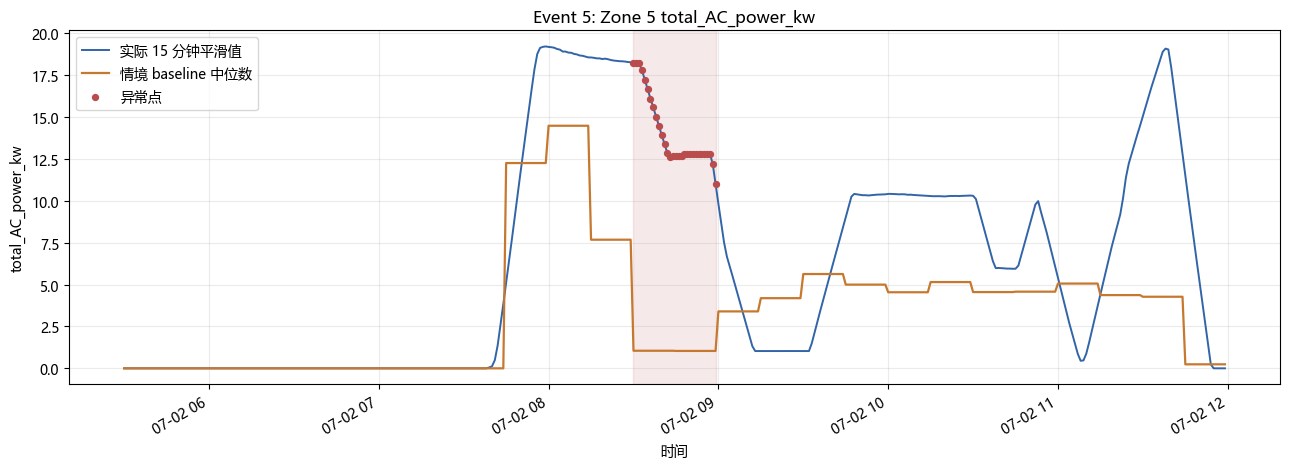

In [13]:
def plot_event(event_row: pd.Series, window_minutes: int = 180) -> None:
    start = pd.to_datetime(event_row["start_time"]) - pd.Timedelta(minutes=window_minutes)
    end = pd.to_datetime(event_row["end_time"]) + pd.Timedelta(minutes=window_minutes)
    subset = scores[
        (scores["zone"] == event_row["zone"])
        & (scores["variable"] == event_row["variable"])
        & (scores["timestamp"].between(start, end))
    ].copy()

    fig, ax = plt.subplots(figsize=(13, 4.8))
    ax.plot(subset["timestamp"], subset["actual_value"], label="实际 15 分钟平滑值", color="#3264a8", linewidth=1.4)
    ax.plot(subset["timestamp"], subset["baseline_median"], label="情境 baseline 中位数", color="#c6782f", linewidth=1.6)
    event_mask = subset["is_anomaly"]
    ax.scatter(subset.loc[event_mask, "timestamp"], subset.loc[event_mask, "actual_value"], color="#b94d4d", s=18, label="异常点", zorder=3)
    ax.axvspan(pd.to_datetime(event_row["start_time"]), pd.to_datetime(event_row["end_time"]), color="#b94d4d", alpha=0.12)
    ax.set_title(f"Event {int(event_row['event_id'])}: Zone {event_row['zone']} {event_row['variable']}")
    ax.set_xlabel("时间")
    ax.set_ylabel(event_row["variable"])
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    save_current_figure(f"event_{int(event_row['event_id']):03d}_zone{event_row['zone']}_{event_row['variable']}.png")
    plt.show()


top_events = anomaly_events.head(5).copy()
for _, event in top_events.iterrows():
    plot_event(event)


### 本步骤结果解释

这个 cell 绘制排名最高的 5 个 anomaly events。每张图会显示事件前后窗口中实际 15 分钟平滑值和对应的 contextual baseline median，并用红色点标出最终异常点。

这样做的原因是单纯的分数表不够直观。通过事件图，可以检查异常是否真的明显偏离 baseline，也可以观察异常是突然尖峰、持续升高、持续偏低，还是与某个运行时段转换有关。

这些代表性图适合放入报告中，用来解释 baseline 方法如何发现并呈现异常候选。


## 14. 最终验证

最终验证用于确认所有预期 baseline 输出均已生成，并记录本次统计 baseline 的关键建模设置。


In [14]:
final_validation = pd.DataFrame([{
    "input_dataset": INPUT_DATASET.name,
    "rows_input_wide": len(df),
    "rows_input_long": len(baseline_long),
    "baseline_profile_rows": len(baseline_profile),
    "anomaly_score_rows": len(scores),
    "anomaly_points": int(scores["is_anomaly"].sum()),
    "anomaly_events": len(anomaly_events),
    "robust_z_threshold": ROBUST_Z_THRESHOLD,
    "default_min_persistence_minutes": MIN_PERSISTENCE_MINUTES,
    "period_thresholds": str(PERIOD_ROBUST_Z_THRESHOLDS),
    "dynamic_persistence_rules": "work=30, non_work_energy=30, environment=30",
    "baseline_grouping": " + ".join(BASELINE_GROUP_COLUMNS),
    "operating_periods": ",".join(sorted(df["operating_period"].unique())),
    "table_count": len(list(TABLE_DIR.glob("*.csv"))) + len(list(TABLE_DIR.glob("*.csv.gz"))),
    "figure_count": len(list(FIGURE_DIR.glob("*.png"))),
}])
final_validation.to_csv(TABLE_DIR / "20_final_validation_summary.csv", index=False)

display(final_validation)
safe_print("Baseline 输出目录:", OUTPUT_DIR)
safe_print("Baseline 表格目录:", TABLE_DIR)
safe_print("Baseline 图表目录:", FIGURE_DIR)


,input_dataset,rows_input_wide,rows_input_long,baseline_profile_rows,anomaly_score_rows,anomaly_points,anomaly_events,robust_z_threshold,default_min_persistence_minutes,period_thresholds,dynamic_persistence_rules,baseline_grouping,operating_periods,table_count,figure_count
0,floor6_zone1245_baseline_ready_2018_jul01_sep0...,362864,2177184,4608,2177184,51998,342,3.5,15,"{'core_work': 4.0, 'ramp_up': 4.0, 'ramp_down'...","work=30, non_work_energy=30, environment=30",zone + day_type + fifteen_minute_slot + variable,"core_work,evening_off,night_off,ramp_down,ramp...",20,12


Baseline 输出目录: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware
Baseline 表格目录: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_tables
Baseline 图表目录: d:\REALPOC\Artificial-Intelligence-for-Smart-Building-Log-Analysis\Artificial Intelligence for Smart-Building Log Analysis\outputs\floor6_zone1245_2018_jul01_sep01_statistical_baseline_v3_15min_operation_aware\baseline_figures


### 本步骤结果解释

最终验证表确认本 notebook 已完整生成 v2b baseline 输出：wide 输入 362,864 行，long scoring 表 2,177,184 行，baseline profile 1,152 行，最终异常点 48,219 个，合并后 anomaly events 为 281 个。

同时，验证表记录了关键方法设置：baseline 分组仍为 `zone + day_type + 15min_slot + variable`，但 robust z-score 阈值按运行时段动态调整，持续时间也按场景动态设置。工作时间和过渡时段使用较高阈值以减少误报，夜间和周末使用较敏感阈值以捕捉非工作时间异常。

这个版本的作用是测试规则敏感性。与 v1 相比，v2b 更符合建筑运行逻辑，也更适合生成可排序、可解释、可审查的异常候选清单。
